In [1]:
import random
import pandas as pd

random.seed(42)
rows = []
for machine in ["M1", "M2", "M3"]:
    for h in range(30 * 24):
        ts = pd.Timestamp("2026-09-01") + pd.Timedelta(hours=h)
        temp = random.gauss(70 + (8 if machine == "M3" else 0), 5)
        vib = abs(random.gauss(2.0 + (0.8 if machine == "M2" else 0), 0.6))
        power = random.gauss(15, 2)
        defects = max(0, int(random.gauss(2 + vib, 1.5)))
        rows.append([ts, machine, temp, vib, power, defects])

df = pd.DataFrame(rows, columns=["timestamp", "machine", "temperature_C", "vibration_mm_s", "power_kW", "defects"])

for i in random.sample(range(len(df)), 40):
    df.loc[i, "temperature_C"] = None

df = pd.concat([df, df.sample(15, random_state=1)]).reset_index(drop=True)
df.to_csv("machine_log.csv", index=False)

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('machine_log.csv')

In [4]:
print(df.shape)

(2175, 6)


In [5]:
print(df.dtypes)

timestamp             str
machine               str
temperature_C     float64
vibration_mm_s    float64
power_kW          float64
defects             int64
dtype: object


In [6]:
df.isna().sum()

timestamp          0
machine            0
temperature_C     40
vibration_mm_s     0
power_kW           0
defects            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(15)

In [8]:
df["timestamp"].dtype


<StringDtype(na_value=nan)>

In [9]:
df.head()

,timestamp,machine,temperature_C,vibration_mm_s,power_kW,defects
0,2026-09-01 00:00:00,M1,69.279548,1.896258,14.777368,4
1,2026-09-01 01:00:00,M1,69.362059,1.101588,15.664637,2
2,2026-09-01 02:00:00,M1,68.915207,2.069531,15.464595,5
3,2026-09-01 03:00:00,M1,73.283183,2.066304,13.523357,2
4,2026-09-01 04:00:00,M1,71.231711,2.786648,15.083314,4


In [10]:
def clean(df):
    df = df.drop_duplicates().copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["temperature_C"] = df["temperature_C"].fillna(
        df.groupby("machine")["temperature_C"].transform("median")
    )
    return df

df = clean(df)

In [11]:
df.duplicated().sum()   # 0
df.isna().sum()         # all 0

timestamp         0
machine           0
temperature_C     0
vibration_mm_s    0
power_kW          0
defects           0
dtype: int64

In [12]:
def get_status(temp, vib):
    if temp > 80:
        return "Overheat"
    elif vib > 3.0:
        return "High_Vibration"
    else:
        return "OK"

In [13]:
df["status"] = df.apply(
    lambda row: get_status(row["temperature_C"], row["vibration_mm_s"]), axis=1)

In [14]:
df["status"].value_counts()

status
OK                1570
High_Vibration     321
Overheat           269
Name: count, dtype: int64

In [15]:
summary = df.groupby("machine").agg(
    mean_temp=("temperature_C", "mean"),
    mean_vib=("vibration_mm_s", "max"),
    total_defects=("defects", "sum"),
    overheat_count=("status", lambda x: (x == "Overheat").sum()),
)

In [16]:
summary["total_defects"].idxmax()   # machine with most defects
summary["overheat_count"].idxmax()   # machine that overheats most

'M3'

In [17]:
summary.columns

Index(['mean_temp', 'mean_vib', 'total_defects', 'overheat_count'], dtype='str')

In [18]:
df.columns

Index(['timestamp', 'machine', 'temperature_C', 'vibration_mm_s', 'power_kW',
       'defects', 'status'],
      dtype='str')

In [19]:
df["date"] = df["timestamp"].dt.date

In [20]:
result = df.groupby(["date", "machine"])["temperature_C"].mean()

In [21]:
result.head()

date        machine
2026-09-01  M1         70.660859
            M2         71.088966
            M3         77.787578
2026-09-02  M1         70.352129
            M2         70.775469
Name: temperature_C, dtype: float64

In [22]:
import matplotlib.pyplot as plt

In [23]:
df.head()

,timestamp,machine,temperature_C,vibration_mm_s,power_kW,defects,status,date
0,2026-09-01 00:00:00,M1,69.279548,1.896258,14.777368,4,OK,2026-09-01
1,2026-09-01 01:00:00,M1,69.362059,1.101588,15.664637,2,OK,2026-09-01
2,2026-09-01 02:00:00,M1,68.915207,2.069531,15.464595,5,OK,2026-09-01
3,2026-09-01 03:00:00,M1,73.283183,2.066304,13.523357,2,OK,2026-09-01
4,2026-09-01 04:00:00,M1,71.231711,2.786648,15.083314,4,OK,2026-09-01


In [24]:
df['day'] = df['timestamp'].dt.date
df[["timestamp", "date"]].head()

,timestamp,date
0,2026-09-01 00:00:00,2026-09-01
1,2026-09-01 01:00:00,2026-09-01
2,2026-09-01 02:00:00,2026-09-01
3,2026-09-01 03:00:00,2026-09-01
4,2026-09-01 04:00:00,2026-09-01


In [25]:
result = df.groupby(["day", "machine"])["temperature_C"].mean()
result.head(6)

day         machine
2026-09-01  M1         70.660859
            M2         71.088966
            M3         77.787578
2026-09-02  M1         70.352129
            M2         70.775469
            M3         78.188951
Name: temperature_C, dtype: float64

In [26]:
table = result.unstack()
table.head()

machine,M1,M2,M3
day,,,
2026-09-01,70.660859,71.088966,77.787578
2026-09-02,70.352129,70.775469,78.188951
2026-09-03,70.021221,68.309499,76.236362
2026-09-04,70.715640,70.974534,79.397637
2026-09-05,68.892959,71.318876,77.796350


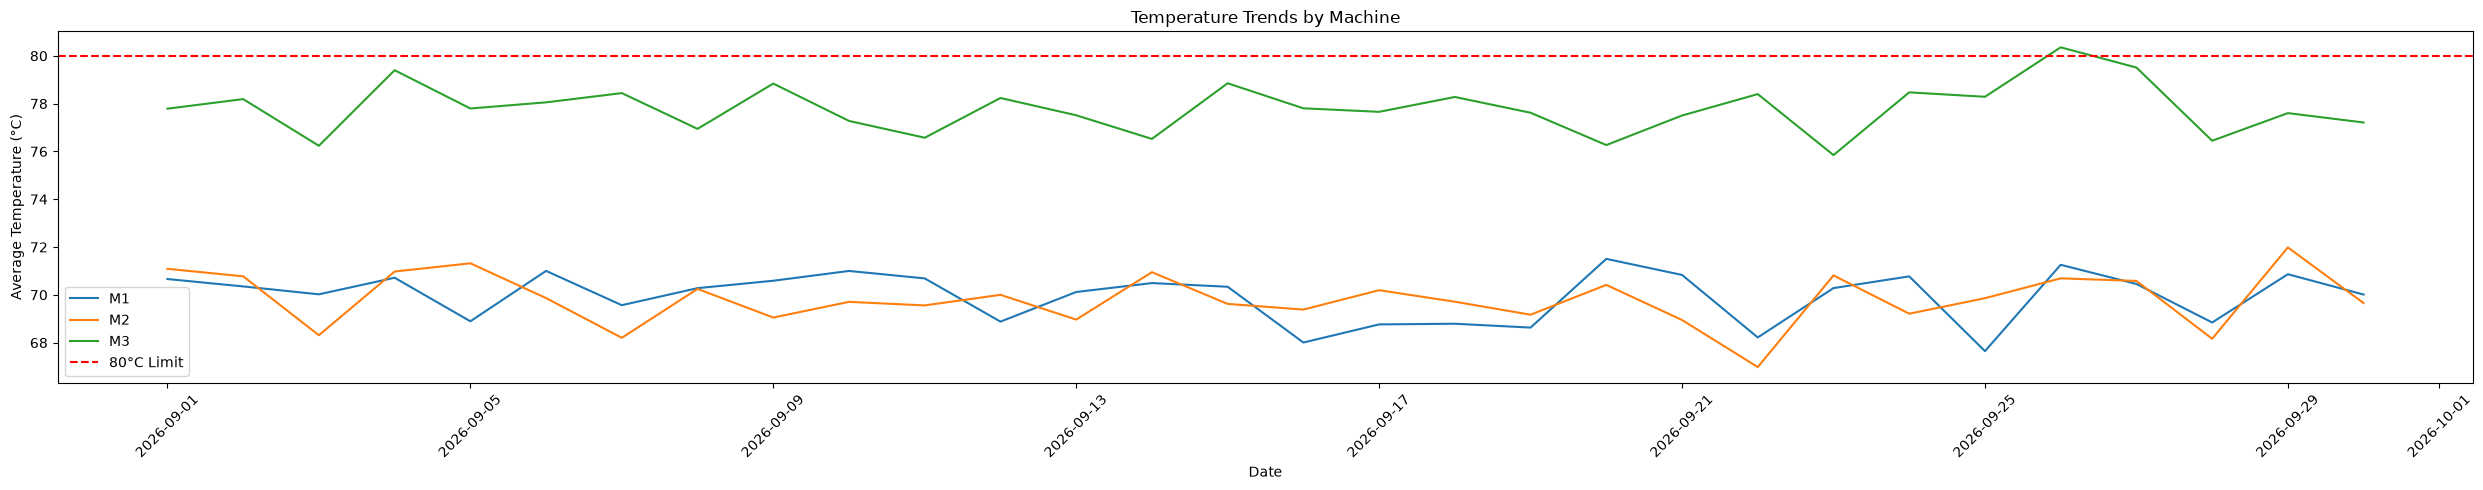

In [27]:
fig, ax = plt.subplots(figsize=(25, 5))

for name in table.columns:
    ax.plot(table.index, table[name], label=name)

ax.axhline(y=80, color='r', linestyle='--', label='80°C Limit')
ax.set_xlabel('Date')
ax.set_ylabel('Average Temperature (°C)')
ax.set_title('Temperature Trends by Machine')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [28]:
m1 = df[df["machine"] == "M1"]

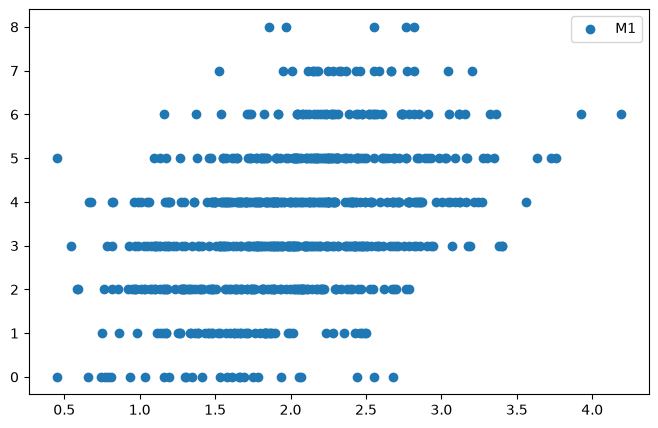

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(m1["vibration_mm_s"], m1["defects"], label="M1")
ax.legend()
plt.show()

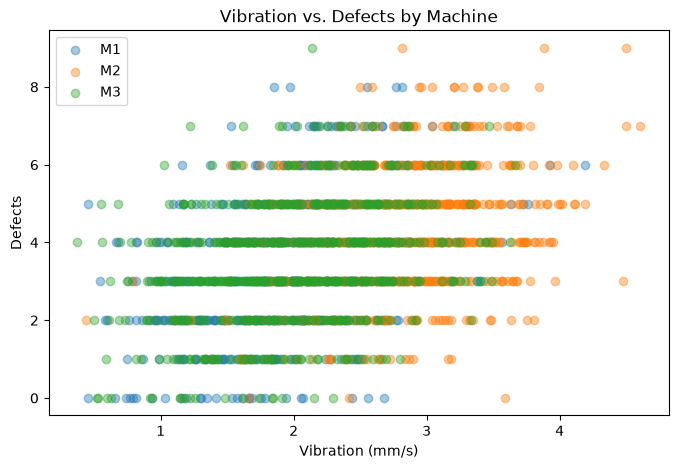

In [30]:
fig, ax = plt.subplots(figsize=(8,5))

for name in df["machine"].unique():
    subset = df[df['machine'] == name]
    ax. scatter(subset["vibration_mm_s"], subset["defects"], label=name, alpha=0.4)

ax.set_xlabel("Vibration (mm/s)")
ax.set_ylabel("Defects")
ax.set_title("Vibration vs. Defects by Machine")
ax.legend()
plt.show()

In [31]:
df["vibration_mm_s"].corr(df["defects"])

np.float64(0.4128330646670111)

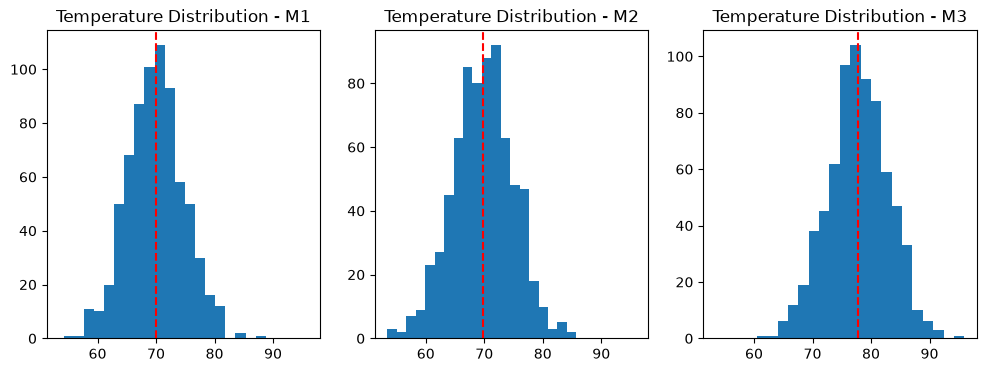

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True)

machines = df['machine'].unique()

for ax, name in zip(axes, machines):
    ax.axvline(df[df['machine'] == name]['temperature_C'].mean(), color="red", linestyle="--")
    subset = df[df['machine'] == name]
    ax.hist(subset['temperature_C'], bins=20)
    ax.set_title(f'Temperature Distribution - {name}')

plt.show()

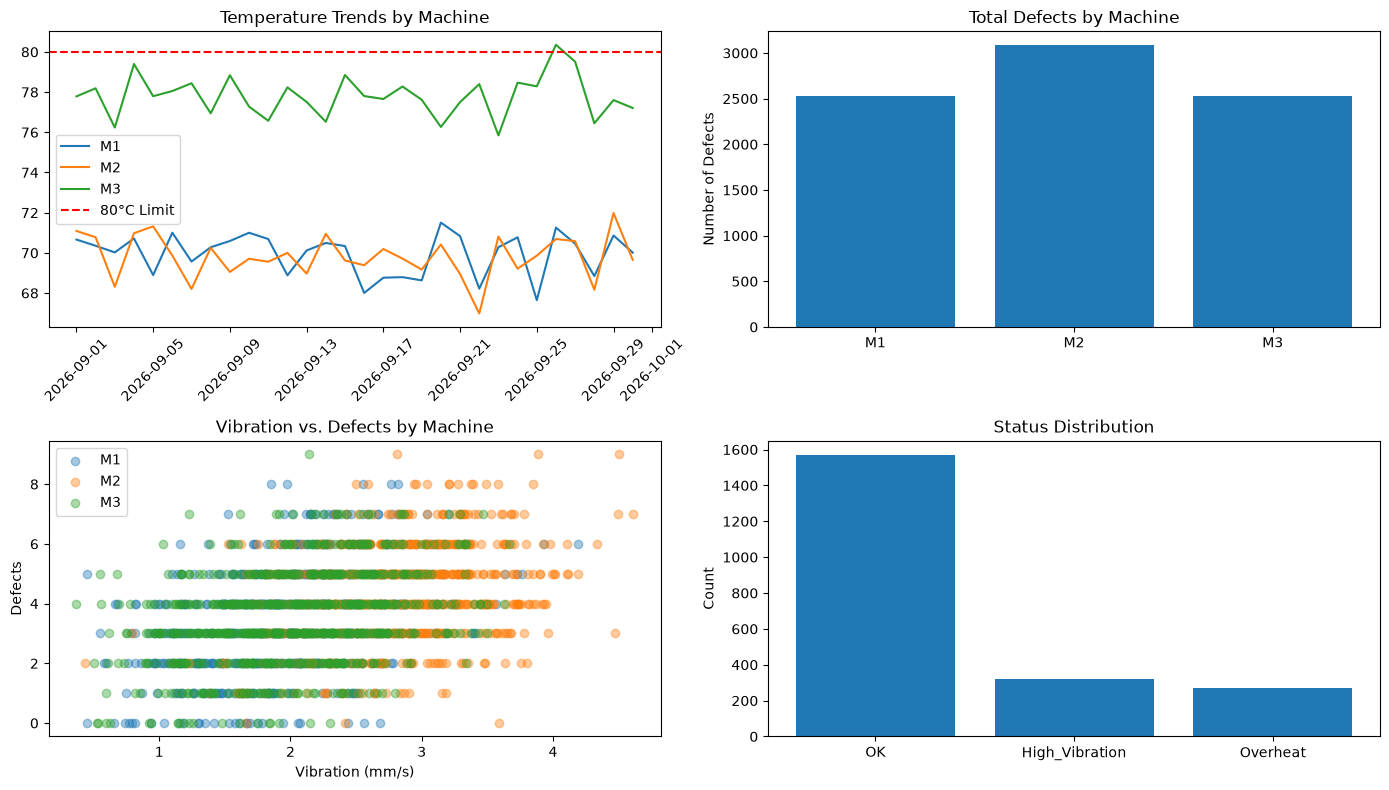

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

#top-left
ax = axes[0,0]
for name in table.columns:
    ax.plot(table.index, table[name], label=name)

ax.axhline(y=80, color='r', linestyle='--', label='80°C Limit')
ax.tick_params(axis="x", rotation=45)
ax.set_title('Temperature Trends by Machine')
ax.legend()

#top-right
totals = df.groupby("machine")["defects"].sum()

ax = axes[0, 1]
ax.bar(totals.index, totals.values)
ax.set_title("Total Defects by Machine")
ax.set_ylabel("Number of Defects")

#bottom-left
ax = axes[1, 0]

for name in df['machine'].unique():
    subset = df[df['machine'] == name]
    ax.scatter(subset['vibration_mm_s'], subset['defects'], label=name, alpha=0.4)
ax.set_title("Vibration vs. Defects by Machine")
ax.set_xlabel("Vibration (mm/s)")
ax.set_ylabel("Defects")
ax.legend()

#bottom-right
counts = df['status'].value_counts()
ax = axes[1, 1]
ax.bar(counts.index, counts.values)
ax.set_title("Status Distribution")
ax.set_ylabel("Count")


plt.tight_layout()
plt.show()

In [34]:
fig.savefig("dashboard.png", dpi=150)

In [37]:
def machine_report(df, machine):
    subset = df[df["machine"] == machine]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(subset["timestamp"], subset["temperature_C"])
    ax.axhline(80, color="red", linestyle="--")
    ax.set_title(f"Temperature: {machine}")
    fig.savefig(f"report_{machine}.png")
    plt.close(fig)
    
    return {
        'machine': machine,
        'avg_temperature': subset["temperature_C"].mean(),
        'max_vibration': subset["vibration_mm_s"].max(),
        'total_defects': subset["defects"].sum(),
        'overheat_hours': (subset['status'] == "overheat").sum()
    }
machine_report(df, "M3")

{'machine': 'M3',
 'avg_temperature': np.float64(77.7969409598438),
 'max_vibration': np.float64(3.665502972763843),
 'total_defects': np.int64(2526),
 'overheat_hours': np.int64(0)}

In [38]:
reports = []
for name in df["machine"].unique():
    reports.append(machine_report(df, name))

report_df = pd.DataFrame(reports)
report_df.sort_values("total_defects", ascending=False)

,machine,avg_temperature,max_vibration,total_defects,overheat_hours
1,M2,69.812737,4.607426,3083,0
0,M1,69.948848,4.187763,2527,0
2,M3,77.796941,3.665503,2526,0
